# Explore the GenCast example dataset

This notebook opens the four-step ERA5 example stored on the D drive and explains its dimensions, coordinates, variables, pressure levels, and timestamps. It then plots representative surface and upper-air fields.

The file is opened lazily, so values are read only when a calculation or plot needs them.

## 1. Install the local analysis packages

Run this once in your selected VS Code Python environment. If the packages are already installed, pip will leave them in place.

In [3]:
#%pip install -q xarray netCDF4 h5netcdf matplotlib pandas numpy

## 2. Open the dataset

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

# On Kaggle, point this at the dataset folder you attached to the notebook
# (Add Input -> your dataset). Locally this still works if the D: drive is
# connected -- just override DATA_DIR below.
import os

KAGGLE_DATASET_SLUG = "your-username/gencast-mini-data"  # @param {type:"string"}
_kaggle_dir = Path("/kaggle/input") / KAGGLE_DATASET_SLUG.split("/")[-1]

if _kaggle_dir.exists():
    DATA_DIR = _kaggle_dir
else:
    DATA_DIR = Path(r"D:\weathernext-data\gencast")  # local fallback

DATA_PATH = DATA_DIR / "dataset" / "source-era5_date-2019-03-29_res-1.0_levels-13_steps-04.nc"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

print(f"File: {DATA_PATH}")
print(f"Size: {DATA_PATH.stat().st_size / 1024**2:.2f} MB")

ds = xr.open_dataset(DATA_PATH)
ds

## 3. Understand the dimensions

Typical dimensions are:

- `batch`: independent forecast examples
- `time`: input and target time steps
- `lat`, `lon`: the global latitude-longitude grid
- `level`: atmospheric pressure levels in hPa

In [4]:
dimensions = pd.DataFrame(
    [{"dimension": name, "size": size} for name, size in ds.sizes.items()]
).set_index("dimension")
dimensions

,size
dimension,
lon,360
lat,181
level,13
time,6
batch,1


In [5]:
for coordinate in ("datetime", "time", "level", "lat", "lon"):
    if coordinate in ds.coords:
        values = ds.coords[coordinate].values
        print(f"{coordinate}: {values[:15]}{' ...' if values.size > 15 else ''}")

datetime: [['2019-03-29T00:00:00.000000000' '2019-03-29T12:00:00.000000000'
  '2019-03-30T00:00:00.000000000' '2019-03-30T12:00:00.000000000'
  '2019-03-31T00:00:00.000000000' '2019-03-31T12:00:00.000000000']]
time: [              0  43200000000000  86400000000000 129600000000000
 172800000000000 216000000000000]
level: [  50  100  150  200  250  300  400  500  600  700  850  925 1000]
lat: [-90. -89. -88. -87. -86. -85. -84. -83. -82. -81. -80. -79. -78. -77.
 -76.] ...
lon: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14.] ...


## 4. Build a variable catalogue

This table tells you which variables are surface fields and which include a pressure-level dimension.

In [6]:
variable_rows = []
for name, variable in ds.data_vars.items():
    variable_rows.append({
        "variable": name,
        "dimensions": " × ".join(variable.dims),
        "shape": str(variable.shape),
        "dtype": str(variable.dtype),
        "units": variable.attrs.get("units", ""),
        "description": variable.attrs.get("long_name", variable.attrs.get("description", "")),
        "size_MB": round(variable.nbytes / 1024**2, 2),
    })

variables = pd.DataFrame(variable_rows).set_index("variable")
pd.set_option("display.max_colwidth", 120)
variables

,dimensions,shape,dtype,units,description,size_MB
variable,,,,,,
land_sea_mask,lat × lon,"(181, 360)",float32,,,0.25
geopotential_at_surface,lat × lon,"(181, 360)",float32,,,0.25
day_progress_cos,batch × time × lon,"(1, 6, 360)",float32,,,0.01
day_progress_sin,batch × time × lon,"(1, 6, 360)",float32,,,0.01
2m_temperature,batch × time × lat × lon,"(1, 6, 181, 360)",float32,,,1.49
sea_surface_temperature,batch × time × lat × lon,"(1, 6, 181, 360)",float32,,,1.49
mean_sea_level_pressure,batch × time × lat × lon,"(1, 6, 181, 360)",float32,,,1.49
10m_v_component_of_wind,batch × time × lat × lon,"(1, 6, 181, 360)",float32,,,1.49
total_precipitation_12hr,batch × time × lat × lon,"(1, 6, 181, 360)",float32,,,1.49


In [7]:
surface_variables = [name for name, value in ds.data_vars.items() if "level" not in value.dims]
pressure_variables = [name for name, value in ds.data_vars.items() if "level" in value.dims]

print("Surface/forcing variables:")
print(surface_variables)
print("\nPressure-level variables:")
print(pressure_variables)

Surface/forcing variables:
['land_sea_mask', 'geopotential_at_surface', 'day_progress_cos', 'day_progress_sin', '2m_temperature', 'sea_surface_temperature', 'mean_sea_level_pressure', '10m_v_component_of_wind', 'total_precipitation_12hr', '10m_u_component_of_wind', 'year_progress_cos', 'year_progress_sin']

Pressure-level variables:
['u_component_of_wind', 'specific_humidity', 'temperature', 'vertical_velocity', 'v_component_of_wind', 'geopotential']


## 5. Plot a surface field

The helper automatically removes `batch` and selects one time. Change `SURFACE_VARIABLE` to another name from the catalogue.

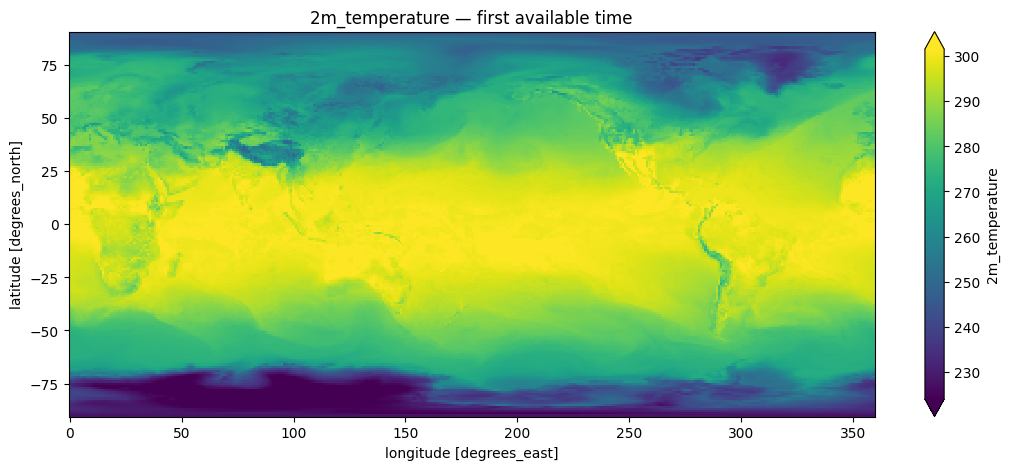

In [8]:
preferred_surface_variables = [
    "2m_temperature",
    "mean_sea_level_pressure",
    "total_precipitation_6hr",
    "10m_wind_speed",
]
SURFACE_VARIABLE = next(
    (name for name in preferred_surface_variables if name in ds.data_vars),
    surface_variables[0],
)

surface = ds[SURFACE_VARIABLE]
if "batch" in surface.dims:
    surface = surface.isel(batch=0)
if "time" in surface.dims:
    surface = surface.isel(time=0)

surface.squeeze(drop=True).plot(figsize=(13, 5), robust=True)
plt.title(f"{SURFACE_VARIABLE} — first available time")
plt.show()

## 6. Plot an atmospheric field at 500 hPa

A 500 hPa map represents conditions in the middle troposphere. Change `PRESSURE_VARIABLE` or `PRESSURE_LEVEL` to explore other fields and levels.

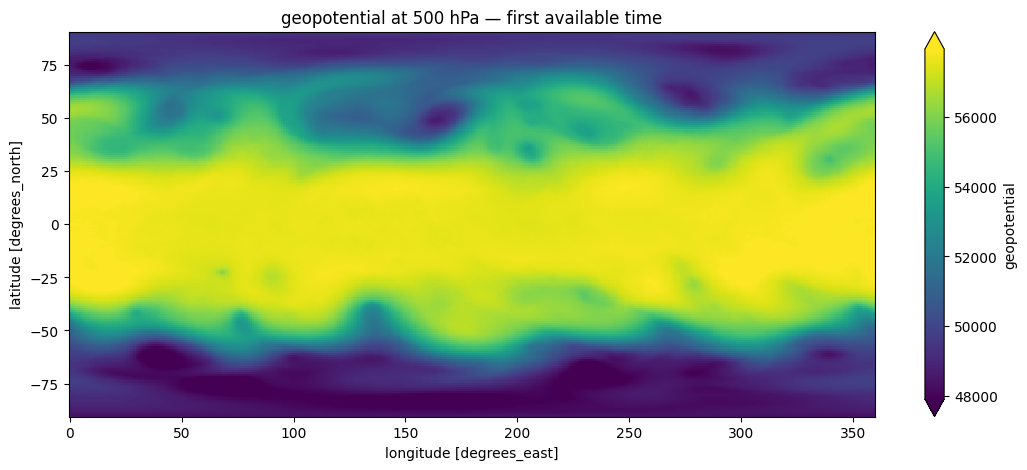

In [9]:
preferred_pressure_variables = [
    "geopotential",
    "temperature",
    "u_component_of_wind",
    "v_component_of_wind",
    "specific_humidity",
]
PRESSURE_VARIABLE = next(
    (name for name in preferred_pressure_variables if name in ds.data_vars),
    pressure_variables[0],
)
PRESSURE_LEVEL = 500

upper_air = ds[PRESSURE_VARIABLE]
if "batch" in upper_air.dims:
    upper_air = upper_air.isel(batch=0)
if "time" in upper_air.dims:
    upper_air = upper_air.isel(time=0)
upper_air = upper_air.sel(level=PRESSURE_LEVEL, method="nearest")

upper_air.squeeze(drop=True).plot(figsize=(13, 5), robust=True)
plt.title(f"{PRESSURE_VARIABLE} at {int(upper_air.level)} hPa — first available time")
plt.show()

## 7. Compare all available times

This produces one panel per time step for the selected surface variable.

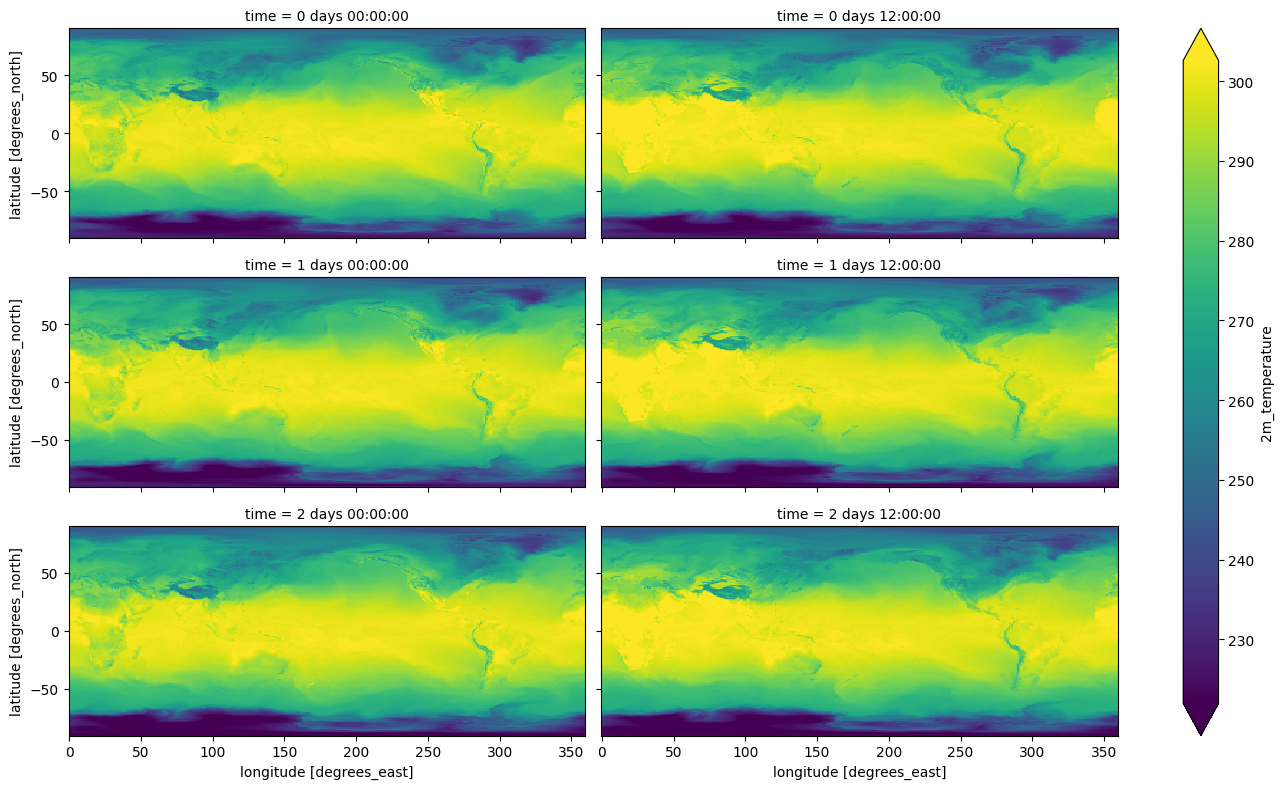

In [10]:
time_series = ds[SURFACE_VARIABLE]
if "batch" in time_series.dims:
    time_series = time_series.isel(batch=0)

if "time" in time_series.dims:
    time_series.plot(
        x="lon",
        y="lat",
        col="time",
        col_wrap=2,
        robust=True,
        figsize=(14, 8),
    )
    plt.show()
else:
    print(f"{SURFACE_VARIABLE} has no time dimension.")

## 8. Basic validation

GenCast expects at least two input times and one target time. This section checks that requirement and reports missing-value percentages without loading every variable simultaneously.

In [11]:
assert ds.sizes.get("time", 0) >= 3, "GenCast requires at least three time steps."

validation_rows = []
for name, variable in ds.data_vars.items():
    missing_percent = float(variable.isnull().mean().compute()) * 100
    validation_rows.append({
        "variable": name,
        "missing_percent": round(missing_percent, 4),
    })

pd.DataFrame(validation_rows).set_index("variable").sort_values("missing_percent", ascending=False)

,missing_percent
variable,
sea_surface_temperature,33.9334
land_sea_mask,0.0000
geopotential_at_surface,0.0000
day_progress_cos,0.0000
day_progress_sin,0.0000
2m_temperature,0.0000
mean_sea_level_pressure,0.0000
10m_v_component_of_wind,0.0000
total_precipitation_12hr,0.0000


## What this file represents

The file is a prepared ERA5 example compatible with the 1-degree, 13-pressure-level GenCast models. It contains two historical input states plus future states used as prediction targets. It is suitable for understanding the pipeline and reproducing a short demonstration, but it is not the full ERA5 training archive.